In [50]:
from pathlib import Path
import re
from typing import Callable, Iterable, Literal
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import rankdata
from statsmodels.formula.api import mixedlm
from statsmodels.graphics.gofplots import qqplot

from HPC_2P_analysis.utils.config import (
    get_itr_index,
    index_to_type,
    select_files,
)
from HPC_2P_analysis.utils.loadData import load_screen_data


CorrMethod = Literal["pearson", "spearman"]
GroupAverage = Literal["by_condition", "by_trial"]
SimilarityMode = Literal["interval", "curve"]
ValueType = Literal["standardized_beta", "raw_beta", "template_corr"]


# Show complete result tables in notebook outputs.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 220)


In [51]:
RULE_LABEL_MAP = {
    "AB_s1e1": "A1",
    "BA_s2e2": "A2",
    "BA_s1e1": "B1",
    "AB_s2e2": "B2",
}


def display_rule_labels(labels: list[str]) -> list[str]:
    return [RULE_LABEL_MAP.get(label, "?") for label in labels]


def upper_tri_offdiag(mat: np.ndarray) -> np.ndarray:
    idx = np.triu_indices_from(mat, k=1)
    return mat[idx]


def zscore_1d(x: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    return (x - np.nanmean(x)) / (np.nanstd(x) + eps)


def make_pure_pattern_position_matrices(
    display_labels: list[str],
) -> tuple[np.ndarray, np.ndarray]:
    """
    display_labels usually:
        ["A1", "A2", "B1", "B2"]

    pattern:
        A vs B

    position:
        1 vs 2
    """
    patterns = [label[0] for label in display_labels]
    positions = [label[1:] for label in display_labels]

    pure_pattern = np.equal.outer(patterns, patterns).astype(float)
    pure_position = np.equal.outer(positions, positions).astype(float)

    return pure_pattern, pure_position


def corr_matrix_from_vectors(
    vectors: list[np.ndarray],
    *,
    method: CorrMethod = "spearman",
    min_neurons: int = 3,
) -> np.ndarray:
    """
    vectors:
        list of four population vectors.

    Returns:
        4 x 4 correlation matrix.
    """
    x = np.stack(vectors, axis=0).astype(float)

    valid = np.all(np.isfinite(x), axis=0)
    x = x[:, valid]

    if x.shape[1] < min_neurons:
        return np.full((len(vectors), len(vectors)), np.nan)

    if np.any(np.nanstd(x, axis=1) < 1e-12):
        return np.full((len(vectors), len(vectors)), np.nan)

    if method == "pearson":
        return np.corrcoef(x)

    if method == "spearman":
        x_rank = np.stack([rankdata(row) for row in x], axis=0)
        return np.corrcoef(x_rank)

    raise ValueError("method must be 'pearson' or 'spearman'")


def compute_pattern_position_value_from_corr(
    corr: np.ndarray,
    labels: list[str],
    *,
    value_type: ValueType = "raw_beta",
    fit_intercept: bool = True,
) -> dict:
    """
    From one 4 x 4 correlation matrix, compute:
        pattern_value
        position_value
    """
    display_labels = display_rule_labels(labels)

    pure_pattern, pure_position = make_pure_pattern_position_matrices(
        display_labels
    )

    y = upper_tri_offdiag(corr)
    x_pattern = upper_tri_offdiag(pure_pattern)
    x_position = upper_tri_offdiag(pure_position)

    valid = (
        np.isfinite(y)
        & np.isfinite(x_pattern)
        & np.isfinite(x_position)
    )

    y = y[valid]
    x_pattern = x_pattern[valid]
    x_position = x_position[valid]

    if len(y) < 3:
        return {
            "labels": display_labels,
            "value_type": value_type,
            "pattern_value": np.nan,
            "position_value": np.nan,
            "intercept": np.nan,
            "pure_pattern": pure_pattern,
            "pure_position": pure_position,
            "observed_offdiag": y,
            "pattern_template_offdiag": x_pattern,
            "position_template_offdiag": x_position,
        }

    if value_type == "raw_beta":
        y_fit = y
        xp_fit = x_pattern
        xq_fit = x_position

    elif value_type == "standardized_beta":
        y_fit = zscore_1d(y)
        xp_fit = zscore_1d(x_pattern)
        xq_fit = zscore_1d(x_position)

    elif value_type == "template_corr":
        pattern_value = float(np.corrcoef(y, x_pattern)[0, 1])
        position_value = float(np.corrcoef(y, x_position)[0, 1])

        return {
            "labels": display_labels,
            "value_type": value_type,
            "pattern_value": pattern_value,
            "position_value": position_value,
            "intercept": np.nan,
            "pure_pattern": pure_pattern,
            "pure_position": pure_position,
            "observed_offdiag": y,
            "pattern_template_offdiag": x_pattern,
            "position_template_offdiag": x_position,
        }

    else:
        raise ValueError(
            "value_type must be 'standardized_beta', "
            "'raw_beta', or 'template_corr'"
        )

    design = np.column_stack([xp_fit, xq_fit])

    if fit_intercept:
        design = np.column_stack([np.ones(len(y_fit)), design])

    beta = np.linalg.lstsq(design, y_fit, rcond=None)[0]

    if fit_intercept:
        intercept = float(beta[0])
        pattern_value = float(beta[1])
        position_value = float(beta[2])
    else:
        intercept = 0.0
        pattern_value = float(beta[0])
        position_value = float(beta[1])

    return {
        "labels": display_labels,
        "value_type": value_type,
        "pattern_value": pattern_value,
        "position_value": position_value,
        "intercept": intercept,
        "pure_pattern": pure_pattern,
        "pure_position": pure_position,
        "observed_offdiag": y,
        "pattern_template_offdiag": x_pattern,
        "position_template_offdiag": x_position,
    }

def get_zone_bounds(
    zones,
    *,
    n_position: int,
    mode: SimilarityMode,
) -> tuple[int, int, int, int]:
    """
    Get two analysis intervals from reward-zone information.

    Returned intervals use Python half-open indexing:
        [s1, e1), [s2, e2)

    mode="curve"
    ------------
    Use the larger intervals between adjacent reward zones:

        interval 1:
            end of zones[0] -> start of zones[2]

        interval 2:
            end of zones[2] -> start of zones[4]

    mode="interval"
    ---------------
    Use the smaller reward-zone intervals:

        interval 1 = zones[1]
        interval 2 = zones[3]
    """
    def first_number(x) -> float:
        values = np.asarray(x).ravel()

        if len(values) < 2:
            raise ValueError(
                f"Each zone must contain at least two bounds, got {values}."
            )

        return float(values[0])

    def second_number(x) -> float:
        values = np.asarray(x).ravel()

        if len(values) < 2:
            raise ValueError(
                f"Each zone must contain at least two bounds, got {values}."
            )

        return float(values[1])

    if mode == "curve":
        # Larger intervals.
        s1 = int(np.floor(second_number(zones[0])))
        e1 = int(np.ceil(first_number(zones[2])))

        s2 = int(np.floor(second_number(zones[2])))
        e2 = int(np.ceil(first_number(zones[4])))

    elif mode == "interval":
        # Smaller reward-zone intervals.
        s1 = int(np.floor(first_number(zones[1])))
        e1 = int(np.ceil(second_number(zones[1])))

        s2 = int(np.floor(first_number(zones[3])))
        e2 = int(np.ceil(second_number(zones[3])))

    else:
        raise ValueError(
            "mode must be 'curve' or 'interval', "
            f"got {mode!r}."
        )

    # Clamp to valid Python indexing range.
    s1 = int(np.clip(s1, 0, n_position))
    e1 = int(np.clip(e1, 0, n_position))
    s2 = int(np.clip(s2, 0, n_position))
    e2 = int(np.clip(e2, 0, n_position))

    if e1 <= s1:
        raise ValueError(
            f"Invalid zone 1 interval for mode={mode!r}: "
            f"[{s1}, {e1})."
        )

    if e2 <= s2:
        raise ValueError(
            f"Invalid zone 2 interval for mode={mode!r}: "
            f"[{s2}, {e2})."
        )

    return s1, e1, s2, e2


def get_track_direction(track_name: str) -> str:
    """
    CAB / ACB / ABC -> AB
    CBA / BCA / BAC -> BA

    couple_ACB / couple_BCA will first remove "couple_".
    """
    base = track_name.replace("couple_", "")

    if base in {"CAB", "ACB", "ABC"}:
        return "AB"

    if base in {"CBA", "BCA", "BAC"}:
        return "BA"

    raise ValueError(f"Trial type not recognized: {track_name}")


def aggregate_label_arrays(
    group_data: dict[str, list[np.ndarray]],
    *,
    labels: list[str],
    group_average: GroupAverage = "by_trial",
) -> dict[str, np.ndarray]:
    """
    Aggregate arrays from multiple trial types.

    interval mode:
        each array shape = (n_neuron, n_trial)

    curve mode:
        each array shape = (n_neuron, n_trial, n_local_position)

    by_trial:
        concatenate trials first, then average trials.

    by_condition:
        average trials within each condition first, then average conditions.
    """
    out = {}

    for label in labels:
        arrays = group_data[label]

        if len(arrays) == 0:
            raise ValueError(f"No data collected for label={label!r}")

        if group_average == "by_trial":
            all_trials = np.concatenate(arrays, axis=1)
            out[label] = np.nanmean(all_trials, axis=1)

        elif group_average == "by_condition":
            condition_means = [
                np.nanmean(arr, axis=1)
                for arr in arrays
            ]

            out[label] = np.nanmean(
                np.stack(condition_means, axis=0),
                axis=0,
            )

        else:
            raise ValueError(
                "group_average must be 'by_trial' or 'by_condition'"
            )

    return out


def collect_similarity_vectors(
    file_path,
    *,
    ana_tt: Iterable[str],
    ana_bt: Iterable[str] = ("Correct",),
    mode: SimilarityMode = "interval",
    group_average: GroupAverage = "by_trial",
    screen_mode: str = "masked",
) -> dict:
    """
    Core data extraction.

    interval mode:
        1. slice zone interval
        2. average neural activity within interval
        3. aggregate trials / conditions
        4. later compute population similarity

    curve mode:
        keep each relative position in the two intervals.
    """
    file_path = Path(file_path)

    data = load_screen_data(
        file_path,
        screen_mode=screen_mode,
    )

    labels = [
        "AB_s1e1",
        "BA_s2e2",
        "BA_s1e1",
        "AB_s2e2",
    ]

    group_data = {label: [] for label in labels}

    n_position = None

    for tt_idx, bt_idx in get_itr_index(data, ana_tt, ana_bt):
        fr = data["firing"][tt_idx, bt_idx]

        if fr is not None and fr.shape[1] > 0:
            n_position = fr.shape[2]
            break

    if n_position is None:
        raise ValueError(f"No valid firing data found in {file_path}")

    s1, e1, s2, e2 = get_zone_bounds(
        data["zones"],
        n_position=n_position,
        mode=mode,
    )

    len1 = e1 - s1
    len2 = e2 - s2

    if mode == "curve":
        if len1 != len2:
            raise ValueError(
                "Curve mode requires equal interval length. "
                f"Got len1={len1}, len2={len2}, "
                f"intervals=({s1}, {e1}), ({s2}, {e2})."
            )

        local_len = len1

    elif mode == "interval":
        local_len = None

    else:
        raise ValueError("mode must be 'interval' or 'curve'")

    for tt_idx, bt_idx in get_itr_index(data, ana_tt, ana_bt):
        fr = data["firing"][tt_idx, bt_idx]

        if fr is None or fr.shape[1] == 0:
            continue

        track_name, _ = index_to_type(data, tt_idx, bt_idx)
        direction = get_track_direction(track_name)

        if mode == "interval":
            # First average activity within each interval for each neuron/trial,
            # then compute population similarity later.
            seg1 = np.nanmean(fr[:, :, s1:e1], axis=2)
            seg2 = np.nanmean(fr[:, :, s2:e2], axis=2)

        else:
            seg1 = fr[:, :, s1:e1]
            seg2 = fr[:, :, s2:e2]

        group_data[f"{direction}_s1e1"].append(seg1)
        group_data[f"{direction}_s2e2"].append(seg2)

    vectors = aggregate_label_arrays(
        group_data,
        labels=labels,
        group_average=group_average,
    )

    meta = dict(data.get("file_info", {}))
    meta["analysis_file_path"] = str(file_path)
    meta["analysis_file_name"] = file_path.name

    return {
        "labels": labels,
        "vectors": vectors,
        "mode": mode,
        "ana_tt": tuple(ana_tt),
        "ana_bt": tuple(ana_bt),
        "group_average": group_average,
        "screen_mode": screen_mode,
        "intervals": {
            "s1": s1,
            "e1": e1,
            "s2": s2,
            "e2": e2,
            "len1": len1,
            "len2": len2,
            "local_len": local_len,
            "pos1": None if local_len is None else np.arange(s1, e1),
            "pos2": None if local_len is None else np.arange(s2, e2),
        },
        "meta": meta,
    }

def compute_similarity(
    file_path,
    *,
    ana_tt: Iterable[str],
    ana_bt: Iterable[str] = ("Correct",),
    mode: SimilarityMode = "interval",
    group_average: GroupAverage = "by_trial",
    corr_method: CorrMethod = "spearman",
    value_type: ValueType = "raw_beta",
    screen_mode: str = "masked",
) -> dict:
    """
    One file -> similarity result.

    mode="interval":
        returns one pattern_value and one position_value.

    mode="curve":
        returns pattern_curve and position_curve.
    """
    base = collect_similarity_vectors(
        file_path,
        ana_tt=ana_tt,
        ana_bt=ana_bt,
        mode=mode,
        group_average=group_average,
        screen_mode=screen_mode,
    )

    labels = base["labels"]
    vectors = base["vectors"]

    if mode == "interval":
        corr = corr_matrix_from_vectors(
            [vectors[label] for label in labels],
            method=corr_method,
        )

        values = compute_pattern_position_value_from_corr(
            corr,
            labels,
            value_type=value_type,
        )

        return {
            **base,
            "corr": corr,
            "values": values,
            "pattern_value": values["pattern_value"],
            "position_value": values["position_value"],
            "intercept": values["intercept"],
            "corr_method": corr_method,
            "value_type": value_type,
        }

    if mode == "curve":
        local_len = base["intervals"]["local_len"]

        corr_mats = np.full((local_len, 4, 4), np.nan)
        pattern_curve = np.full(local_len, np.nan)
        position_curve = np.full(local_len, np.nan)
        intercept_curve = np.full(local_len, np.nan)

        values_by_position = []

        for pos_idx in range(local_len):
            pos_vectors = [
                vectors[label][:, pos_idx]
                for label in labels
            ]

            corr = corr_matrix_from_vectors(
                pos_vectors,
                method=corr_method,
            )

            values = compute_pattern_position_value_from_corr(
                corr,
                labels,
                value_type=value_type,
            )

            corr_mats[pos_idx] = corr
            pattern_curve[pos_idx] = values["pattern_value"]
            position_curve[pos_idx] = values["position_value"]
            intercept_curve[pos_idx] = values["intercept"]
            values_by_position.append(values)

        return {
            **base,
            "corr_mats": corr_mats,
            "pattern_curve": pattern_curve,
            "position_curve": position_curve,
            "intercept_curve": intercept_curve,
            "values_by_position": values_by_position,
            "position_index": np.arange(local_len),
            "corr_method": corr_method,
            "value_type": value_type,
        }

    raise ValueError("mode must be 'interval' or 'curve'")


def format_tuple(x) -> str:
    if x is None:
        return "None"

    if isinstance(x, str):
        return x

    return ",".join(str(v) for v in x)


def get_reward_mode_suffix(reward_mode) -> str:
    """
    Convert reward mode into display suffix.

    Rule:
        full / None / empty string -> no suffix
        other values, e.g. 75     -> _75

    This avoids exposing a global REWARD_MODES list in the notebook.
    Validation is left to select_files() / load_data file_info parsing.
    """
    if reward_mode is None:
        return ""

    reward_mode = str(reward_mode).strip().lower()

    if reward_mode in {"", "full", "none"}:
        return ""

    return f"_{reward_mode}"


def append_reward_mode_suffix(
    label: str,
    reward_mode,
) -> str:
    """
    Append reward-mode suffix only when reward_mode is not full.
    """
    label = str(label)
    suffix = get_reward_mode_suffix(reward_mode)

    if suffix == "":
        return label

    if label.endswith(suffix):
        return label

    return f"{label}{suffix}"


def make_group_name(
    base_group: str,
    reward_mode="full",
) -> str:
    """
    Helper used by run_* cells.

    Examples
    --------
    make_group_name("pattern", "full") -> "pattern"
    make_group_name("pattern", "75")   -> "pattern_75"
    """
    return append_reward_mode_suffix(base_group, reward_mode)


def resolve_group_label(
    meta: dict,
    group: str | Callable[[dict], str] | None = None,
) -> str:
    """
    Resolve final plotting group.

    reward_mode display rule:
        full -> transparent, no suffix
        75   -> add _75
    """
    if group is None:
        base_group = meta.get("task_type", "unknown")

    elif callable(group):
        base_group = str(group(meta))

    else:
        base_group = str(group)

    return append_reward_mode_suffix(
        base_group,
        meta.get("reward_mode", "full"),
    )


def similarity_result_to_rows(
    result: dict,
    *,
    group: str | Callable[[dict], str] | None = None,
    analysis_name: str | None = None,
) -> list[dict]:
    """
    Convert one result into dataframe rows.

    interval:
        one row per file.

    curve:
        one row per file per relative position.
    """
    meta = dict(result["meta"])

    out_group = resolve_group_label(meta, group)
    source_group = meta.get("task_type", "unknown")

    base_row = {
        **meta,
        "group": out_group,
        "source_group": source_group,
        "analysis_name": analysis_name,
        "mode": result["mode"],
        "screen_mode": result["screen_mode"],
        "ana_tt": format_tuple(result["ana_tt"]),
        "ana_bt": format_tuple(result["ana_bt"]),
        "group_average": result["group_average"],
        "corr_method": result["corr_method"],
        "value_type": result["value_type"],
    }

    if result["mode"] == "interval":
        return [{
            **base_row,
            "pattern_value": float(result["pattern_value"]),
            "position_value": float(result["position_value"]),
            "intercept": float(result["intercept"]),
        }]

    if result["mode"] == "curve":
        rows = []

        pos1 = result["intervals"]["pos1"]
        pos2 = result["intervals"]["pos2"]

        for i, pos_idx in enumerate(result["position_index"]):
            rows.append({
                **base_row,
                "position_index": int(pos_idx),
                "pos1": int(pos1[i]),
                "pos2": int(pos2[i]),
                "pattern_value": float(result["pattern_curve"][i]),
                "position_value": float(result["position_curve"][i]),
                "intercept": float(result["intercept_curve"][i]),
            })

        return rows

    raise ValueError("result['mode'] must be 'interval' or 'curve'")

from collections.abc import Mapping

SIMILARITY_COLORS = {
    "pattern": "#4C78A8",
    "position": "#F2A541",
}

SIMILARITY_LABELS = {
    "pattern": "Pattern similarity",
    "position": "Position similarity",
}

LEARNING_PATTERN = re.compile(
    r"(?<![A-Za-z0-9])L[ _]*([+-]?\s*\d+)(?!\d)",
    flags=re.IGNORECASE,
)


def extract_learning_day(value) -> int | None:
    """Extract one integer L label from a filename-like value."""
    if value is None or (not isinstance(value, (str, Path)) and pd.isna(value)):
        return None

    matches = LEARNING_PATTERN.findall(str(value))
    if len(matches) == 0:
        return None
    if len(matches) != 1:
        raise ValueError(f"Expected one L label, got {matches!r}: {value!r}")
    return int(matches[0].replace(" ", ""))


def _coalesce_learning_day(row: pd.Series) -> int | None:
    value = row.get("learning_day")
    if value is not None and not pd.isna(value):
        return int(value)

    for column in ("learning_label", "file_name", "source_stem", "file_path"):
        if column in row:
            value = extract_learning_day(row[column])
            if value is not None:
                return value
    return None


def extract_longitudinal_mouse_id(row: pd.Series, mouse_col: str) -> str | None:
    """Extract stable mouse ID, removing any session-date suffix."""
    candidates = []
    for column in (mouse_col, "mouse_base_id", "mouse_id", "source_stem", "file_name", "file_path"):
        if column in row and pd.notna(row[column]):
            candidates.append(str(row[column]))
            if column == "file_path":
                path = Path(str(row[column]))
                candidates.extend((path.parent.name, path.stem))

    date_patterns = (
        r"(?P<mouse>[A-Za-z][A-Za-z0-9]*?)[-_](?:19|20)\d{2}[-_]?[01]\d[-_]?[0-3]\d(?:$|[^0-9])",
        r"(?P<mouse>[A-Za-z][A-Za-z0-9]*?)[-_]\d{2}[01]\d[0-3]\d(?:$|[^0-9])",
    )
    for candidate in candidates:
        variants = (candidate, Path(candidate).name, Path(candidate).stem)
        for variant in variants:
            for pattern in date_patterns:
                match = re.search(pattern, variant)
                if match is not None:
                    return match.group("mouse")

    for candidate in candidates:
        candidate = Path(candidate).name
        match = re.search(r"\b(HPC?\d+)\b", candidate, flags=re.IGNORECASE)
        if match is not None:
            return match.group(1).upper()
    return None


def _normalize_mouse_column(df: pd.DataFrame, mouse_col: str) -> pd.Series:
    if mouse_col not in df.columns:
        raise KeyError(f"Missing mouse column: {mouse_col!r}")
    mouse = df[mouse_col].astype("string").str.strip()
    if mouse.isna().any() or (mouse == "").any():
        raise ValueError(f"{mouse_col!r} contains missing/empty mouse IDs.")
    return mouse.astype(str)


def prepare_longitudinal_similarity_table(
    similarity_df: pd.DataFrame,
    *,
    mouse_col: str = "mouse_base_id",
    date_col: str = "session_date",
    pattern_col: str = "pattern_value",
    position_col: str = "position_value",
    require_l0: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Validate alignment, warn about invalid rows/mice, and skip them."""
    df = similarity_df.copy()
    required = {mouse_col, date_col, pattern_col, position_col}
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"Missing required columns: {sorted(missing)}")

    raw_mouse = df.apply(
        lambda row: extract_longitudinal_mouse_id(row, mouse_col),
        axis=1,
    ).astype("string")
    df["mouse"] = raw_mouse
    df["session_date"] = pd.to_datetime(df[date_col], errors="coerce")
    df["learning_session"] = df.apply(_coalesce_learning_day, axis=1)
    df["pattern_similarity"] = pd.to_numeric(df[pattern_col], errors="coerce")
    df["position_similarity"] = pd.to_numeric(df[position_col], errors="coerce")

    reasons = pd.Series("", index=df.index, dtype="string")
    reasons.loc[raw_mouse.isna() | (raw_mouse == "")] = "missing_mouse_id"
    reasons.loc[df["session_date"].isna()] = "missing_or_invalid_session_date"
    reasons.loc[df["learning_session"].isna()] = "missing_explicit_L_label"
    metric_missing = ~np.isfinite(
        df[["pattern_similarity", "position_similarity"]]
    ).all(axis=1)
    reasons.loc[metric_missing] = "missing_or_nonfinite_similarity"

    excluded_parts = []
    invalid_rows = df.loc[reasons != ""].copy()
    if len(invalid_rows) > 0:
        invalid_rows["invalid_reason"] = reasons.loc[reasons != ""].to_numpy()
        invalid_rows["exclusion_stage"] = "row_validation"
        excluded_parts.append(invalid_rows)
        for row_index, row in invalid_rows.iterrows():
            warnings.warn(
                f"Skipping invalid longitudinal row {row_index}: "
                f"{row['invalid_reason']}",
                RuntimeWarning,
                stacklevel=2,
            )

    out = df.loc[reasons == ""].copy()
    out["mouse"] = out["mouse"].astype(str)
    out["learning_session"] = out["learning_session"].astype(int)
    out["learning_label"] = "L" + out["learning_session"].astype(str)

    invalid_mice = {}
    for mouse, group in out.groupby("mouse", sort=True):
        duplicate = group.duplicated("learning_session", keep=False)
        if duplicate.any():
            invalid_mice[mouse] = "duplicate_learning_session"
            continue
        ordered = group.sort_values("learning_session")
        sessions = ordered["learning_session"].tolist()
        dates = ordered["session_date"].tolist()
        if require_l0 and 0 not in sessions:
            invalid_mice[mouse] = "missing_explicit_L0"
        elif dates != sorted(dates) or len(dates) != len(set(dates)):
            invalid_mice[mouse] = "learning_session_date_order_invalid"

    for mouse, reason in invalid_mice.items():
        group = out.loc[out["mouse"] == mouse].copy()
        group["invalid_reason"] = reason
        group["exclusion_stage"] = "mouse_alignment"
        excluded_parts.append(group)
        warnings.warn(
            f"Skipping mouse {mouse!r} from longitudinal analysis: {reason}",
            RuntimeWarning,
            stacklevel=2,
        )
    if invalid_mice:
        out = out.loc[~out["mouse"].isin(invalid_mice)].copy()

    if len(out) == 0:
        raise ValueError(
            "No valid explicitly L-labelled mouse-session observations remain."
        )

    l0_dates = (
        out.loc[out["learning_session"] == 0, ["mouse", "session_date"]]
        .rename(columns={"session_date": "l0_date"})
    )
    out = out.merge(l0_dates, on="mouse", how="left", validate="many_to_one")
    out["days_since_l0"] = (out["session_date"] - out["l0_date"]).dt.days
    out["valid"] = True
    out["invalid_reason"] = ""

    ordered_columns = [
        "mouse", "session_date", "learning_session", "learning_label",
        "l0_date", "days_since_l0", "pattern_similarity",
        "position_similarity", "valid", "invalid_reason",
    ]
    other = [column for column in out.columns if column not in ordered_columns]
    out = out[ordered_columns + other].sort_values(
        ["mouse", "learning_session"]
    ).reset_index(drop=True)

    excluded = (
        pd.concat(excluded_parts, ignore_index=True, sort=False)
        if excluded_parts
        else pd.DataFrame()
    )
    return out, excluded


def make_long_similarity_table(wide_df: pd.DataFrame) -> pd.DataFrame:
    """Convert aligned session rows to one row per metric per mouse-session."""
    id_columns = [
        column for column in wide_df.columns
        if column not in {"pattern_similarity", "position_similarity"}
    ]
    long_df = wide_df.melt(
        id_vars=id_columns,
        value_vars=["pattern_similarity", "position_similarity"],
        var_name="similarity_column",
        value_name="similarity",
    )
    long_df["similarity_type"] = long_df["similarity_column"].str.replace(
        "_similarity", "", regex=False
    )
    return long_df.drop(columns="similarity_column")


def summarize_session_coverage(wide_df: pd.DataFrame) -> pd.DataFrame:
    """Count independent mice and session observations at each aligned L."""
    return (
        wide_df.groupby("learning_session", as_index=False)
        .agg(
            n_mice=("mouse", "nunique"),
            n_observations=("mouse", "size"),
            min_date=("session_date", "min"),
            max_date=("session_date", "max"),
        )
        .sort_values("learning_session")
        .reset_index(drop=True)
    )


def _is_singular(result, tolerance: float = 1e-8) -> bool:
    covariance = np.asarray(result.cov_re, dtype=float)
    if covariance.size == 0 or not np.isfinite(covariance).all():
        return True
    eigenvalues = np.linalg.eigvalsh(covariance)
    scale = max(1.0, float(np.max(np.abs(eigenvalues))))
    return bool(np.min(eigenvalues) <= tolerance * scale)


def _fit_mixed_model(
    data: pd.DataFrame,
    *,
    predictor: str,
    random_slope: bool,
    reml: bool = True,
):
    re_formula = f"~{predictor}" if random_slope else "1"
    model = mixedlm(
        f"similarity ~ {predictor}",
        data=data,
        groups=data["mouse"],
        re_formula=re_formula,
        missing="raise",
    )
    captured = []
    last_error = None
    for method in ("lbfgs", "powell", "cg"):
        try:
            with warnings.catch_warnings(record=True) as records:
                warnings.simplefilter("always")
                result = model.fit(
                    reml=reml,
                    method=method,
                    maxiter=2000,
                    disp=False,
                )
            captured.extend(str(record.message) for record in records)
            if bool(result.converged):
                return result, method, captured
        except Exception as exc:  # statsmodels optimizers expose varied errors
            last_error = exc
            captured.append(f"{method}: {type(exc).__name__}: {exc}")
    if last_error is not None:
        raise RuntimeError("Mixed model failed: " + " | ".join(captured)) from last_error
    raise RuntimeError("Mixed model did not converge: " + " | ".join(captured))


def fit_linear_mixed_model(
    metric_df: pd.DataFrame,
    *,
    predictor: str,
    version: str,
    similarity_type: str,
    prefer_random_slope: bool = True,
    fallback_to_random_intercept: bool = True,
    singular_tolerance: float = 1e-8,
    reml: bool = True,
) -> dict:
    """Fit one metric independently, falling back to a random intercept."""
    columns = ["mouse", "similarity", predictor]
    data = metric_df.loc[:, columns].dropna().copy()
    data["similarity"] = pd.to_numeric(data["similarity"], errors="coerce")
    data[predictor] = pd.to_numeric(data[predictor], errors="coerce")
    data = data.loc[np.isfinite(data[["similarity", predictor]]).all(axis=1)]

    n_mouse = data["mouse"].nunique()
    n_observation = len(data)
    n_mice_with_repeated_observations = int(
        (data.groupby("mouse").size() >= 2).sum()
    )
    predictor_has_variation = data[predictor].nunique() >= 2
    if (
        n_mouse < 2
        or n_observation <= n_mouse
        or n_mice_with_repeated_observations < 2
        or not predictor_has_variation
    ):
        return {
            "valid": False,
            "invalid_reason": "insufficient_mice_or_observations",
            "version": version,
            "similarity": similarity_type,
            "predictor": predictor,
            "n_mice": n_mouse,
            "n_observations": n_observation,
            "n_mice_with_repeated_observations": n_mice_with_repeated_observations,
            "result": None,
            "data": data,
        }

    structures = (
        [True, False]
        if prefer_random_slope and fallback_to_random_intercept
        else [True]
        if prefer_random_slope
        else [False]
    )
    attempts = []
    selected = None
    for random_slope in structures:
        try:
            result, optimizer, warning_messages = _fit_mixed_model(
                data,
                predictor=predictor,
                random_slope=random_slope,
                reml=reml,
            )
            singular = _is_singular(result, tolerance=singular_tolerance)
            attempts.append({
                "random_slope": random_slope,
                "converged": bool(result.converged),
                "singular": singular,
                "optimizer": optimizer,
                "warnings": warning_messages,
            })
            if random_slope and singular:
                continue
            selected = (result, random_slope, singular, optimizer, warning_messages)
            break
        except Exception as exc:
            attempts.append({
                "random_slope": random_slope,
                "converged": False,
                "singular": None,
                "optimizer": None,
                "warnings": [f"{type(exc).__name__}: {exc}"],
            })

    if selected is None:
        return {
            "valid": False,
            "invalid_reason": "all_random_effect_structures_failed",
            "version": version,
            "similarity": similarity_type,
            "predictor": predictor,
            "n_mice": n_mouse,
            "n_observations": n_observation,
            "n_mice_with_repeated_observations": n_mice_with_repeated_observations,
            "attempts": attempts,
            "result": None,
            "data": data,
        }

    result, random_slope, singular, optimizer, warning_messages = selected
    estimate = float(result.fe_params[predictor])
    standard_error = float(result.bse_fe[predictor])
    ci = result.conf_int().loc[predictor]
    intercept = float(result.fe_params["Intercept"])
    intercept_se = float(result.bse_fe["Intercept"])
    intercept_ci = result.conf_int().loc["Intercept"]
    predictor_sd = float(data[predictor].std(ddof=1))
    outcome_sd = float(data["similarity"].std(ddof=1))
    standardized_slope = (
        estimate * predictor_sd / outcome_sd
        if predictor_sd > 0 and outcome_sd > 0 else np.nan
    )
    covariance = np.asarray(result.cov_re, dtype=float)
    random_intercept_variance = float(covariance[0, 0])
    random_slope_variance = (
        float(covariance[1, 1]) if random_slope else np.nan
    )
    random_covariance = float(covariance[0, 1]) if random_slope else np.nan
    random_correlation = (
        random_covariance
        / np.sqrt(random_intercept_variance * random_slope_variance)
        if random_slope
        and random_intercept_variance > 0
        and random_slope_variance > 0
        else np.nan
    )

    return {
        "valid": True,
        "invalid_reason": "",
        "version": version,
        "similarity": similarity_type,
        "predictor": predictor,
        "estimate": estimate,
        "se": standard_error,
        "ci_low": float(ci.iloc[0]),
        "ci_high": float(ci.iloc[1]),
        "p_value": float(result.pvalues[predictor]),
        "standardized_slope": standardized_slope,
        "predictor_sd": predictor_sd,
        "outcome_sd": outcome_sd,
        "intercept": intercept,
        "intercept_se": intercept_se,
        "intercept_ci_low": float(intercept_ci.iloc[0]),
        "intercept_ci_high": float(intercept_ci.iloc[1]),
        "intercept_p_value": float(result.pvalues["Intercept"]),
        "random_effect_structure": (
            f"(1 + {predictor} | mouse)" if random_slope else "(1 | mouse)"
        ),
        "random_intercept_variance": random_intercept_variance,
        "random_intercept_sd": np.sqrt(max(random_intercept_variance, 0)),
        "random_slope_variance": random_slope_variance,
        "random_slope_sd": (
            np.sqrt(max(random_slope_variance, 0))
            if random_slope else np.nan
        ),
        "random_intercept_slope_covariance": random_covariance,
        "random_intercept_slope_correlation": random_correlation,
        "residual_variance": float(result.scale),
        "converged": bool(result.converged),
        "singular": bool(singular),
        "optimizer": optimizer,
        "warning_messages": " | ".join(dict.fromkeys(warning_messages)),
        "n_mice": n_mouse,
        "n_observations": n_observation,
        "n_mice_with_repeated_observations": n_mice_with_repeated_observations,
        "attempts": attempts,
        "result": result,
        "data": data,
    }


def model_result_row(model_output: Mapping) -> dict:
    """Remove non-tabular model objects and return one tidy summary row."""
    keys = [
        "version", "similarity", "predictor", "estimate", "se", "ci_low",
        "ci_high", "p_value", "standardized_slope", "predictor_sd",
        "outcome_sd", "intercept", "intercept_se", "intercept_ci_low",
        "intercept_ci_high", "intercept_p_value", "random_effect_structure",
        "random_intercept_variance", "random_intercept_sd",
        "random_slope_variance", "random_slope_sd",
        "random_intercept_slope_covariance",
        "random_intercept_slope_correlation", "residual_variance",
        "converged", "singular", "optimizer", "warning_messages",
        "n_mice", "n_observations", "n_mice_with_repeated_observations",
        "valid", "invalid_reason",
    ]
    return {key: model_output.get(key, np.nan) for key in keys}


def fit_primary_models(
    long_df: pd.DataFrame,
    *,
    version: str,
    predictor: str = "learning_session",
    fallback_to_random_intercept: bool = True,
) -> tuple[dict[str, dict], pd.DataFrame]:
    """Fit Pattern and Position models independently."""
    outputs = {}
    rows = []
    for similarity_type in ("pattern", "position"):
        metric_df = long_df.loc[long_df["similarity_type"] == similarity_type]
        output = fit_linear_mixed_model(
            metric_df,
            predictor=predictor,
            version=version,
            similarity_type=similarity_type,
            fallback_to_random_intercept=fallback_to_random_intercept,
        )
        outputs[similarity_type] = output
        rows.append(model_result_row(output))
    return outputs, pd.DataFrame(rows)


def fit_random_intercept_only_models(
    long_df: pd.DataFrame,
    *,
    version: str,
    predictor: str = "learning_session",
) -> tuple[dict[str, dict], pd.DataFrame]:
    """Fit the same fixed slope with a forced mouse random intercept only."""
    outputs = {}
    rows = []
    for similarity_type in ("pattern", "position"):
        metric_df = long_df.loc[
            long_df["similarity_type"] == similarity_type
        ]
        output = fit_linear_mixed_model(
            metric_df,
            predictor=predictor,
            version=version,
            similarity_type=similarity_type,
            prefer_random_slope=False,
        )
        outputs[similarity_type] = output
        rows.append(model_result_row(output))
    return outputs, pd.DataFrame(rows)


def make_intercept_slope_effect_table(
    *model_tables: pd.DataFrame,
) -> pd.DataFrame:
    """Create a focused fixed/random intercept and slope effect table."""
    table = pd.concat(model_tables, ignore_index=True, sort=False)
    columns = [
        "version", "similarity", "random_effect_structure",
        "intercept", "intercept_se", "intercept_ci_low",
        "intercept_ci_high", "intercept_p_value",
        "estimate", "se", "ci_low", "ci_high", "p_value",
        "standardized_slope", "random_intercept_variance",
        "random_intercept_sd", "random_slope_variance",
        "random_slope_sd", "random_intercept_slope_covariance",
        "random_intercept_slope_correlation", "residual_variance",
        "converged", "singular", "optimizer", "warning_messages",
        "n_mice", "n_observations", "valid", "invalid_reason",
    ]
    return table.loc[:, columns]


def fit_models_with_structure(
    long_df: pd.DataFrame,
    *,
    version: str,
    predictor: str,
    random_effect_structure: str = "intercept_only",
) -> tuple[dict[str, dict], pd.DataFrame]:
    """Fit both metrics using one explicitly selected random structure."""
    allowed = {"intercept_only", "intercept_slope"}
    if random_effect_structure not in allowed:
        raise ValueError(
            f"random_effect_structure must be one of {sorted(allowed)}, "
            f"got {random_effect_structure!r}."
        )
    if random_effect_structure == "intercept_only":
        return fit_random_intercept_only_models(
            long_df,
            version=version,
            predictor=predictor,
        )
    return fit_primary_models(
        long_df,
        version=version,
        predictor=predictor,
        fallback_to_random_intercept=False,
    )


def make_compact_inference_table(model_table: pd.DataFrame) -> pd.DataFrame:
    """Keep the core fixed effects and variance terms visible without truncation."""
    return model_table[[
        "version", "similarity", "random_effect_structure",
        "intercept", "intercept_se", "intercept_ci_low",
        "intercept_ci_high", "intercept_p_value",
        "estimate", "se", "ci_low", "ci_high", "p_value",
        "standardized_slope", "random_intercept_variance",
        "random_intercept_sd", "random_slope_variance",
        "random_slope_sd", "residual_variance", "n_mice",
        "n_observations", "converged", "singular", "optimizer",
    ]].rename(columns={
        "estimate": "slope",
        "se": "slope_se",
        "ci_low": "slope_ci_low",
        "ci_high": "slope_ci_high",
        "p_value": "slope_p_value",
    })


def fixed_effect_prediction(
    model_output: Mapping,
    x_values: Iterable[float],
) -> pd.DataFrame:
    """Predict population fixed-effect trend and Wald 95% confidence interval."""
    if not model_output.get("valid", False):
        return pd.DataFrame(columns=["x", "estimate", "ci_low", "ci_high"])

    result = model_output["result"]
    predictor = model_output["predictor"]
    x = np.asarray(list(x_values), dtype=float)
    names = list(result.fe_params.index)
    design = np.column_stack([
        np.ones_like(x) if name == "Intercept" else x
        if name == predictor else np.zeros_like(x)
        for name in names
    ])
    beta = result.fe_params.loc[names].to_numpy(float)
    covariance = result.cov_params().loc[names, names].to_numpy(float)
    estimate = design @ beta
    variance = np.einsum("ij,jk,ik->i", design, covariance, design)
    se = np.sqrt(np.maximum(variance, 0))
    return pd.DataFrame({
        "x": x,
        "estimate": estimate,
        "ci_low": estimate - 1.96 * se,
        "ci_high": estimate + 1.96 * se,
    })


def progression_time_correlations(wide_df: pd.DataFrame) -> pd.DataFrame:
    """Compute descriptive Pearson and Spearman association of L with elapsed days."""
    data = wide_df[["learning_session", "days_since_l0"]].dropna()
    rows = []
    for method in ("pearson", "spearman"):
        if len(data) < 3 or data.nunique().min() < 2:
            coefficient = p_value = np.nan
            valid = False
            reason = "insufficient_variation_or_observations"
        else:
            test = stats.pearsonr if method == "pearson" else stats.spearmanr
            coefficient, p_value = test(
                data["learning_session"], data["days_since_l0"]
            )
            valid = True
            reason = ""
        rows.append({
            "method": method,
            "coefficient": coefficient,
            "p_value": p_value,
            "n_observations": len(data),
            "n_mice": wide_df.loc[data.index, "mouse"].nunique(),
            "valid": valid,
            "invalid_reason": reason,
        })
    return pd.DataFrame(rows)


def _format_learning_tick(value: float) -> str:
    integer = int(round(value))
    return f"L{integer}"


def _format_p_value(p_value: float) -> str:
    if not np.isfinite(p_value):
        return "p = NA"
    if p_value < 0.001:
        return "p < 0.001"
    return f"p = {p_value:.3f}"


def _p_to_stars(p_value: float) -> str:
    if not np.isfinite(p_value):
        return "NA"
    if p_value < 0.001:
        return "***"
    if p_value < 0.01:
        return "**"
    if p_value < 0.05:
        return "*"
    return "ns"


def plot_longitudinal_similarity(
    long_df: pd.DataFrame,
    model_output: Mapping,
    *,
    similarity_type: str,
    ax=None,
    detailed: bool = True,
):
    """Draw one metric on a supplied axis without creating extra windows."""
    if similarity_type not in {"pattern", "position"}:
        raise ValueError("similarity_type must be 'pattern' or 'position'.")
    data = long_df.loc[long_df["similarity_type"] == similarity_type].copy()
    sessions = np.sort(data["learning_session"].dropna().unique())
    if len(sessions) == 0:
        raise ValueError(f"No {similarity_type} observations available.")
    if ax is None:
        _, ax = plt.subplots(figsize=(5.8, 4.7))

    color = SIMILARITY_COLORS[similarity_type]
    if detailed:
        markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "h"]
        mice = sorted(data["mouse"].unique())
        marker_by_mouse = {
            mouse: markers[index % len(markers)]
            for index, mouse in enumerate(mice)
        }
        for mouse, group in data.groupby("mouse", sort=True):
            group = group.sort_values("learning_session")
            ax.plot(
                group["learning_session"], group["similarity"],
                color=color, alpha=0.52, linewidth=1.75,
                marker=marker_by_mouse[mouse], markersize=6.5,
                markeredgecolor="white", markeredgewidth=0.45, zorder=1,
            )

    if model_output.get("valid", False):
        grid = np.linspace(float(sessions.min()), float(sessions.max()), 250)
        prediction = fixed_effect_prediction(model_output, grid)
        ax.fill_between(
            prediction["x"], prediction["ci_low"], prediction["ci_high"],
            color=color, alpha=0.20, linewidth=0, zorder=2,
        )
        ax.plot(
            prediction["x"], prediction["estimate"],
            color=color, linewidth=3.6, zorder=3,
        )
        p_value = model_output["p_value"]
        p_text = f"{_format_p_value(p_value)}  {_p_to_stars(p_value)}"
    else:
        p_text = "p = NA"

    ax.text(
        0.97, 0.95, p_text, transform=ax.transAxes,
        ha="right", va="top", color="#222222", fontsize=13,
    )
    ax.axvline(0, color="#222222", linestyle="--", linewidth=2.0, zorder=0)
    ax.set_xticks(sessions)
    ax.set_xticklabels(
        [_format_learning_tick(value) for value in sessions], fontsize=12,
    )
    ax.set_xlabel("Learning session", fontsize=14)
    ax.set_ylabel(f"{similarity_type.capitalize()} similarity", fontsize=14)
    ax.tick_params(axis="both", labelsize=12, width=1.3, length=5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set_linewidth(1.4)
    return ax


def plot_model_diagnostics(
    model_outputs: Mapping[str, Mapping],
    *,
    title: str,
    figsize: tuple[float, float] = (14.0, 8.2),
):
    """Plot scale-correct residual diagnostics for both metrics."""
    fig, axes = plt.subplots(2, 3, figsize=figsize)
    for row, similarity_type in enumerate(("pattern", "position")):
        output = model_outputs[similarity_type]
        ax_resid, ax_qq, ax_hist = axes[row]
        if not output.get("valid", False):
            reason = output.get("invalid_reason", "invalid")
            for axis in (ax_resid, ax_qq, ax_hist):
                axis.text(0.5, 0.5, reason, ha="center", va="center")
            continue

        result = output["result"]
        residual = np.asarray(result.resid, dtype=float)
        fitted = np.asarray(result.fittedvalues, dtype=float)
        residual_sd = float(np.sqrt(max(result.scale, np.finfo(float).eps)))
        standardized = residual / residual_sd
        finite = np.isfinite(standardized) & np.isfinite(fitted)
        residual = residual[finite]
        fitted = fitted[finite]
        standardized = standardized[finite]
        color = SIMILARITY_COLORS[similarity_type]
        label = SIMILARITY_LABELS[similarity_type]

        ax_resid.scatter(
            fitted, standardized, color=color, alpha=0.72,
            s=35, edgecolor="white", linewidth=0.45,
        )
        ax_resid.axhline(0, color="#444444", linestyle="--", linewidth=1.4)
        ax_resid.axhline(2, color="#999999", linestyle=":", linewidth=1.0)
        ax_resid.axhline(-2, color="#999999", linestyle=":", linewidth=1.0)
        ax_resid.set_xlabel("Fitted value", fontsize=12, fontweight="bold")
        ax_resid.set_ylabel("Standardized conditional residual", fontsize=12, fontweight="bold")
        ax_resid.set_title(f"{label}: residual vs fitted", fontsize=13, fontweight="bold")

        stats.probplot(standardized, dist="norm", plot=ax_qq)
        qq_lines = ax_qq.get_lines()
        if qq_lines:
            qq_lines[0].set_markerfacecolor(color)
            qq_lines[0].set_markeredgecolor("white")
            qq_lines[0].set_markersize(6)
            qq_lines[0].set_alpha(0.78)
        if len(qq_lines) > 1:
            qq_lines[1].set_color("#333333")
            qq_lines[1].set_linewidth(1.5)
        ax_qq.set_xlabel("Theoretical standard-normal quantiles", fontsize=12, fontweight="bold")
        ax_qq.set_ylabel("Standardized residual quantiles", fontsize=12, fontweight="bold")
        ax_qq.set_title(f"{label}: standardized QQ", fontsize=13, fontweight="bold")

        bins = min(12, max(5, int(np.sqrt(len(standardized)))))
        ax_hist.hist(
            standardized, bins=bins, density=True, color=color,
            alpha=0.55, edgecolor="white", linewidth=0.8,
        )
        x_grid = np.linspace(
            min(-3.5, standardized.min() - 0.3),
            max(3.5, standardized.max() + 0.3),
            300,
        )
        ax_hist.plot(
            x_grid, stats.norm.pdf(x_grid), color="#333333",
            linewidth=2.0, label="N(0, 1)",
        )
        skewness = stats.skew(standardized, bias=False) if len(standardized) >= 3 else np.nan
        excess_kurtosis = (
            stats.kurtosis(standardized, fisher=True, bias=False)
            if len(standardized) >= 4 else np.nan
        )
        shapiro_p = (
            stats.shapiro(standardized).pvalue
            if 3 <= len(standardized) <= 5000 else np.nan
        )
        ax_hist.text(
            0.97, 0.95,
            f"n = {len(standardized)}\n"
            f"skew = {skewness:.2f}\n"
            f"excess kurtosis = {excess_kurtosis:.2f}\n"
            f"Shapiro {_format_p_value(shapiro_p)}",
            transform=ax_hist.transAxes,
            ha="right", va="top", fontsize=10, fontweight="bold",
            bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85},
        )
        ax_hist.set_xlabel("Standardized conditional residual", fontsize=12, fontweight="bold")
        ax_hist.set_ylabel("Density", fontsize=12, fontweight="bold")
        ax_hist.set_title(f"{label}: residual distribution", fontsize=13, fontweight="bold")
        ax_hist.legend(frameon=False, fontsize=10)

    for axis in axes.flat:
        axis.spines[["top", "right"]].set_visible(False)
        axis.spines[["bottom", "left"]].set_linewidth(1.2)
        axis.tick_params(labelsize=10, width=1.1)
    fig.suptitle(title, fontsize=17, fontweight="bold", y=1.01)
    fig.tight_layout()
    return fig, axes



In [52]:
DATA_ROOT = Path("../../../data/HPC_2p/screen")
OUTPUT_DIR = Path("../../../results/HPC_2p/longitudinal_similarity")
REWARD_MODE = "full"  # Run "75" separately; do not pool reward modes.
COUPLE_TRACKS = ("couple_ACB", "couple_BCA")
RANDOM_EFFECT_STRUCTURE = "intercept_only"
# Options: "intercept_only" or "intercept_slope"
STRIP_L5_L6 = False
# False: use all L0+ sessions. True: restrict analysis to L0-L4.
STRIP_MAX_SESSION = 4


def analyze_longitudinal_similarity_files(
    file_df: pd.DataFrame,
    *,
    ana_tt: tuple[str, ...] = COUPLE_TRACKS,
    ana_bt: tuple[str, ...] = ("Correct",),
    screen_mode: str = "masked",
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Compute canonical similarity per file; warn and skip invalid files."""
    rows = []
    skipped = []

    for row_index, file_row in file_df.reset_index(drop=True).iterrows():
        file_path = Path(file_row["file_path"])
        try:
            result = compute_similarity(
                file_path,
                ana_tt=ana_tt,
                ana_bt=ana_bt,
                mode="interval",
                group_average="by_trial",
                corr_method="spearman",
                value_type="raw_beta",
                screen_mode=screen_mode,
            )
            for column, value in file_row.items():
                result["meta"][column] = value
            result_rows = similarity_result_to_rows(
                result,
                group="couple",
                analysis_name="couple_longitudinal",
            )
            if len(result_rows) != 1:
                raise ValueError(
                    f"Expected one interval row, got {len(result_rows)}."
                )
            output_row = result_rows[0]
            values = np.asarray(
                [output_row["pattern_value"], output_row["position_value"]],
                dtype=float,
            )
            if not np.isfinite(values).all():
                raise ValueError(
                    "Pattern or Position similarity is non-finite."
                )
            rows.append(output_row)
        except Exception as exc:
            message = (
                f"Skipping invalid similarity file {file_path}: "
                f"{type(exc).__name__}: {exc}"
            )
            warnings.warn(message, RuntimeWarning, stacklevel=2)
            skipped.append({
                "row_index": row_index,
                "file_path": str(file_path),
                "file_name": file_path.name,
                "error_type": type(exc).__name__,
                "invalid_reason": str(exc),
            })

    if len(rows) == 0:
        raise ValueError(
            "No valid Couple files remain after similarity calculation."
        )

    return pd.DataFrame(rows), pd.DataFrame(skipped)


couple_file_df = select_files(
    DATA_ROOT,
    task_type="couple",
    reward_mode=REWARD_MODE,
    file_kind="pickle",
    recursive=True,
)
if len(couple_file_df) == 0:
    raise ValueError(f"No Couple screen files found under {DATA_ROOT}")

couple_file_df = couple_file_df.copy()
couple_file_df["learning_session"] = couple_file_df.apply(
    _coalesce_learning_day,
    axis=1,
)
n_unlabelled_couple = int(couple_file_df["learning_session"].isna().sum())
couple_file_df = couple_file_df.loc[
    couple_file_df["learning_session"].notna()
].reset_index(drop=True)
if len(couple_file_df) == 0:
    raise ValueError("No explicitly L-labelled Couple files remain.")

similarity_df, skipped_similarity_files = analyze_longitudinal_similarity_files(
    couple_file_df
)
if len(skipped_similarity_files) > 0:
    metadata = couple_file_df.reset_index(drop=True).copy()
    metadata["row_index"] = metadata.index
    metadata["mouse"] = metadata.apply(
        lambda row: extract_longitudinal_mouse_id(row, "mouse_id"),
        axis=1,
    )
    metadata["session_date"] = metadata.apply(
        lambda row: pd.to_datetime(
            re.search(
                r"(?:19|20)\d{2}[-_]\d{2}[-_]\d{2}",
                str(row.get("file_name", row.get("file_path", ""))),
            ).group(0).replace("_", "-")
            if re.search(
                r"(?:19|20)\d{2}[-_]\d{2}[-_]\d{2}",
                str(row.get("file_name", row.get("file_path", ""))),
            ) else pd.NaT
        ),
        axis=1,
    )
    skipped_similarity_files = skipped_similarity_files.merge(
        metadata[["row_index", "mouse", "session_date"]],
        on="row_index",
        how="left",
        validate="one_to_one",
    )

print("Similarity calculation summary")
print(
    f"Valid files: {len(similarity_df)}; "
    f"silently excluded files without L labels: {n_unlabelled_couple}; "
    f"failed files: {len(skipped_similarity_files)}"
)
print("Preview of valid session-level Pattern and Position similarity values")
display(similarity_df.head())
print("Files excluded because similarity could not be calculated")
display(skipped_similarity_files)

file_similarity_table = (
    similarity_df.assign(
        mouse=similarity_df.apply(
            lambda row: extract_longitudinal_mouse_id(row, "mouse_id"),
            axis=1,
        ),
        learning_session=similarity_df.apply(
            _coalesce_learning_day,
            axis=1,
        ),
        session_date=pd.to_datetime(
            similarity_df["session_date"], errors="coerce"
        ),
    )
    .sort_values(["mouse", "learning_session", "session_date"])
    [[
        "mouse", "session_date", "learning_session", "file_name",
        "pattern_value", "position_value", "corr_method",
        "value_type",
    ]]
    .rename(columns={
        "pattern_value": "pattern_similarity",
        "position_value": "position_similarity",
    })
    .reset_index(drop=True)
)
print("All valid files sorted by mouse, learning session, and recording date")
display(file_similarity_table)


/home/wangym/tmp/ipykernel_2409448/434161600.py:101: RuntimeWarning: Skipping invalid similarity file ../../../data/HPC_2p/screen/HP07/HP07_2025-02-23_couple_L-1_screen.pkl: ValueError: Pattern or Position similarity is non-finite.
  similarity_df, skipped_similarity_files = analyze_longitudinal_similarity_files(
/home/wangym/tmp/ipykernel_2409448/434161600.py:101: RuntimeWarning: Skipping invalid similarity file ../../../data/HPC_2p/screen/HP24/HP24_2025-07-15_couple_L-6_screen.pkl: ValueError: No valid firing data found in ../../../data/HPC_2p/screen/HP24/HP24_2025-07-15_couple_L-6_screen.pkl
  similarity_df, skipped_similarity_files = analyze_longitudinal_similarity_files(
/home/wangym/tmp/ipykernel_2409448/434161600.py:101: RuntimeWarning: Skipping invalid similarity file ../../../data/HPC_2p/screen/HP24/HP24_2025-07-16_couple_L-5_screen.pkl: ValueError: No valid firing data found in ../../../data/HPC_2p/screen/HP24/HP24_2025-07-16_couple_L-5_screen.pkl
  similarity_df, skipped_sim

Similarity calculation summary
Valid files: 64; silently excluded files without L labels: 1; failed files: 10
Preview of valid session-level Pattern and Position similarity values


,mouse_id,file_path,file_name,suffix,file_kind,source_stem,task_type,reward_mode,track_type_id,behavior_type_id,learning_day,learning_label,session_date,session_key,analysis_file_path,analysis_file_name,learning_session,group,source_group,analysis_name,mode,screen_mode,ana_tt,ana_bt,group_average,corr_method,value_type,pattern_value,position_value,intercept
0,HP01_2024_12_03,../../../data/HPC_2p/screen/HP01/HP01_2024-12-03_couple_L0_screen.pkl,HP01_2024-12-03_couple_L0_screen.pkl,.pkl,pickle,HP01_2024_12_03_couple_L0,couple,full,2,0,0,L0,2024-12-03,20241203,../../../data/HPC_2p/screen/HP01/HP01_2024-12-03_couple_L0_screen.pkl,HP01_2024-12-03_couple_L0_screen.pkl,0.0,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.757946,0.025911,0.123536
1,HP01_2024_12_04,../../../data/HPC_2p/screen/HP01/HP01_2024-12-04_couple_L1_screen.pkl,HP01_2024-12-04_couple_L1_screen.pkl,.pkl,pickle,HP01_2024_12_04_couple_L1,couple,full,2,0,1,L1,2024-12-04,20241204,../../../data/HPC_2p/screen/HP01/HP01_2024-12-04_couple_L1_screen.pkl,HP01_2024-12-04_couple_L1_screen.pkl,1.0,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.697065,0.062415,0.139402
2,HP01_2024_12_06,../../../data/HPC_2p/screen/HP01/HP01_2024-12-06_couple_L2_screen.pkl,HP01_2024-12-06_couple_L2_screen.pkl,.pkl,pickle,HP01_2024_12_06_couple_L2,couple,full,2,0,2,L2,2024-12-06,20241206,../../../data/HPC_2p/screen/HP01/HP01_2024-12-06_couple_L2_screen.pkl,HP01_2024-12-06_couple_L2_screen.pkl,2.0,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.625498,0.148451,0.074940
3,HP01_2024_12_07,../../../data/HPC_2p/screen/HP01/HP01_2024-12-07_couple_L3_screen.pkl,HP01_2024-12-07_couple_L3_screen.pkl,.pkl,pickle,HP01_2024_12_07_couple_L3,couple,full,2,0,3,L3,2024-12-07,20241207,../../../data/HPC_2p/screen/HP01/HP01_2024-12-07_couple_L3_screen.pkl,HP01_2024-12-07_couple_L3_screen.pkl,3.0,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.418769,0.309706,0.080233
4,HP01_2024_12_09,../../../data/HPC_2p/screen/HP01/HP01_2024-12-09_couple_L4_screen.pkl,HP01_2024-12-09_couple_L4_screen.pkl,.pkl,pickle,HP01_2024_12_09_couple_L4,couple,full,2,0,4,L4,2024-12-09,20241209,../../../data/HPC_2p/screen/HP01/HP01_2024-12-09_couple_L4_screen.pkl,HP01_2024-12-09_couple_L4_screen.pkl,4.0,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.549528,0.188110,0.027451


Files excluded because similarity could not be calculated


,row_index,file_path,file_name,error_type,invalid_reason,mouse,session_date
0,17,../../../data/HPC_2p/screen/HP07/HP07_2025-02-23_couple_L-1_screen.pkl,HP07_2025-02-23_couple_L-1_screen.pkl,ValueError,Pattern or Position similarity is non-finite.,HP07,2025-02-23
1,27,../../../data/HPC_2p/screen/HP24/HP24_2025-07-15_couple_L-6_screen.pkl,HP24_2025-07-15_couple_L-6_screen.pkl,ValueError,No valid firing data found in ../../../data/HPC_2p/screen/HP24/HP24_2025-07-15_couple_L-6_screen.pkl,HP24,2025-07-15
2,28,../../../data/HPC_2p/screen/HP24/HP24_2025-07-16_couple_L-5_screen.pkl,HP24_2025-07-16_couple_L-5_screen.pkl,ValueError,No valid firing data found in ../../../data/HPC_2p/screen/HP24/HP24_2025-07-16_couple_L-5_screen.pkl,HP24,2025-07-16
3,29,../../../data/HPC_2p/screen/HP24/HP24_2025-07-17_couple_L-4_screen.pkl,HP24_2025-07-17_couple_L-4_screen.pkl,ValueError,Pattern or Position similarity is non-finite.,HP24,2025-07-17
4,38,../../../data/HPC_2p/screen/HP27/HP27_2025-07-28_couple_L-2_screen.pkl,HP27_2025-07-28_couple_L-2_screen.pkl,ValueError,No valid firing data found in ../../../data/HPC_2p/screen/HP27/HP27_2025-07-28_couple_L-2_screen.pkl,HP27,2025-07-28
5,39,../../../data/HPC_2p/screen/HP27/HP27_2025-07-29_couple_L-1_screen.pkl,HP27_2025-07-29_couple_L-1_screen.pkl,ValueError,Pattern or Position similarity is non-finite.,HP27,2025-07-29
6,43,../../../data/HPC_2p/screen/HP28/HP28_2025-07-29_couple_L-1_screen.pkl,HP28_2025-07-29_couple_L-1_screen.pkl,ValueError,Pattern or Position similarity is non-finite.,HP28,2025-07-29
7,48,../../../data/HPC_2p/screen/HP29/HP29_2025-07-28_couple_L-1_screen.pkl,HP29_2025-07-28_couple_L-1_screen.pkl,ValueError,No valid firing data found in ../../../data/HPC_2p/screen/HP29/HP29_2025-07-28_couple_L-1_screen.pkl,HP29,2025-07-28
8,49,../../../data/HPC_2p/screen/HP29/HP29_2025-07-29_couple_L0_screen.pkl,HP29_2025-07-29_couple_L0_screen.pkl,ValueError,Pattern or Position similarity is non-finite.,HP29,2025-07-29
9,53,../../../data/HPC_2p/screen/HP31/HP31_2025-09-02_couple_L-3_screen.pkl,HP31_2025-09-02_couple_L-3_screen.pkl,ValueError,Pattern or Position similarity is non-finite.,HP31,2025-09-02


All valid files sorted by mouse, learning session, and recording date


,mouse,session_date,learning_session,file_name,pattern_similarity,position_similarity,corr_method,value_type
0,HP01,2024-12-03,0,HP01_2024-12-03_couple_L0_screen.pkl,7.579463e-01,0.025911,spearman,raw_beta
1,HP01,2024-12-04,1,HP01_2024-12-04_couple_L1_screen.pkl,6.970651e-01,0.062415,spearman,raw_beta
2,HP01,2024-12-06,2,HP01_2024-12-06_couple_L2_screen.pkl,6.254983e-01,0.148451,spearman,raw_beta
3,HP01,2024-12-07,3,HP01_2024-12-07_couple_L3_screen.pkl,4.187686e-01,0.309706,spearman,raw_beta
4,HP01,2024-12-09,4,HP01_2024-12-09_couple_L4_screen.pkl,5.495281e-01,0.188110,spearman,raw_beta
5,HP01,2024-12-10,5,HP01_2024-12-10_couple_L5_screen.pkl,5.338200e-01,0.135565,spearman,raw_beta
6,HP01,2024-12-11,6,HP01_2024-12-11_couple_L6_screen.pkl,4.508632e-01,0.293376,spearman,raw_beta
7,HP02,2024-12-06,-1,HP02_2024-12-06_couple_L-1_screen.pkl,3.181818e-02,0.827273,spearman,raw_beta
8,HP02,2024-12-07,0,HP02_2024-12-07_couple_L0_screen.pkl,3.608032e-01,0.019391,spearman,raw_beta
9,HP02,2024-12-09,1,HP02_2024-12-09_couple_L1_screen.pkl,3.370771e-01,0.070145,spearman,raw_beta


In [53]:
MOUSE_COLUMN = (
    "mouse_base_id"
    if "mouse_base_id" in similarity_df.columns
    else "mouse_id"
)

aligned_wide, excluded_sessions = prepare_longitudinal_similarity_table(
    similarity_df,
    mouse_col=MOUSE_COLUMN,
    date_col="session_date",
    pattern_col="pattern_value",
    position_col="position_value",
    require_l0=False,
)
aligned_long = make_long_similarity_table(aligned_wide)

if len(skipped_similarity_files) > 0:
    skipped_for_export = skipped_similarity_files.copy()
    skipped_for_export["exclusion_stage"] = "similarity_calculation"
    excluded_sessions["exclusion_stage"] = "learning_alignment"
    excluded_sessions = pd.concat(
        [excluded_sessions, skipped_for_export],
        ignore_index=True,
        sort=False,
    )

print("Learning-aligned data summary")
print(
    f"Aligned observations: {len(aligned_wide)}; "
    f"mice: {aligned_wide['mouse'].nunique()}; "
    f"excluded records: {len(excluded_sessions)}"
)
print("Preview of valid learning-aligned observations")
display(aligned_wide.head())
print("Excluded files or observations and their exclusion reasons")
display(excluded_sessions[[
    column for column in ["mouse", "session_date", "file_name", "invalid_reason"]
    if column in excluded_sessions.columns
]])
# Primary analysis: criterion attainment and continued training only.
post_wide = aligned_wide.loc[
    aligned_wide["learning_session"] >= 0
].copy()
if len(post_wide) == 0:
    raise ValueError("No valid L0-or-later observations remain.")
post_long = make_long_similarity_table(post_wide)
print(
    f"Post-learning observations={len(post_wide)}, "
    f"mice={post_wide['mouse'].nunique()}"
)

primary_mice_without_l0 = sorted(
    aligned_wide.loc[aligned_wide["l0_date"].isna(), "mouse"].unique()
)
for mouse in primary_mice_without_l0:
    warnings.warn(
        f"Mouse {mouse!r} has no valid L0 but is retained in the primary "
        "learning-session analysis; it is excluded only from days-since-L0 "
        "sensitivity analysis.",
        RuntimeWarning,
        stacklevel=2,
    )

if STRIP_L5_L6:
    analysis_wide = post_wide.loc[
        post_wide["learning_session"].between(0, STRIP_MAX_SESSION)
    ].copy()
    analysis_range_label = f"L0-L{STRIP_MAX_SESSION}"
else:
    analysis_wide = post_wide.copy()
    analysis_range_label = "All post-learning sessions"
analysis_long = make_long_similarity_table(analysis_wide)
print(
    f"Selected analysis range: {analysis_range_label}; "
    f"observations={len(analysis_wide)}; "
    f"mice={analysis_wide['mouse'].nunique()}"
)


Learning-aligned data summary
Aligned observations: 64; mice: 13; excluded records: 10
Preview of valid learning-aligned observations


,mouse,session_date,learning_session,learning_label,l0_date,days_since_l0,pattern_similarity,position_similarity,valid,invalid_reason,mouse_id,file_path,file_name,suffix,file_kind,source_stem,task_type,reward_mode,track_type_id,behavior_type_id,learning_day,session_key,analysis_file_path,analysis_file_name,group,source_group,analysis_name,mode,screen_mode,ana_tt,ana_bt,group_average,corr_method,value_type,pattern_value,position_value,intercept
0,HP01,2024-12-03,0,L0,2024-12-03,0.0,0.757946,0.025911,True,,HP01_2024_12_03,../../../data/HPC_2p/screen/HP01/HP01_2024-12-03_couple_L0_screen.pkl,HP01_2024-12-03_couple_L0_screen.pkl,.pkl,pickle,HP01_2024_12_03_couple_L0,couple,full,2,0,0,20241203,../../../data/HPC_2p/screen/HP01/HP01_2024-12-03_couple_L0_screen.pkl,HP01_2024-12-03_couple_L0_screen.pkl,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.757946,0.025911,0.123536
1,HP01,2024-12-04,1,L1,2024-12-03,1.0,0.697065,0.062415,True,,HP01_2024_12_04,../../../data/HPC_2p/screen/HP01/HP01_2024-12-04_couple_L1_screen.pkl,HP01_2024-12-04_couple_L1_screen.pkl,.pkl,pickle,HP01_2024_12_04_couple_L1,couple,full,2,0,1,20241204,../../../data/HPC_2p/screen/HP01/HP01_2024-12-04_couple_L1_screen.pkl,HP01_2024-12-04_couple_L1_screen.pkl,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.697065,0.062415,0.139402
2,HP01,2024-12-06,2,L2,2024-12-03,3.0,0.625498,0.148451,True,,HP01_2024_12_06,../../../data/HPC_2p/screen/HP01/HP01_2024-12-06_couple_L2_screen.pkl,HP01_2024-12-06_couple_L2_screen.pkl,.pkl,pickle,HP01_2024_12_06_couple_L2,couple,full,2,0,2,20241206,../../../data/HPC_2p/screen/HP01/HP01_2024-12-06_couple_L2_screen.pkl,HP01_2024-12-06_couple_L2_screen.pkl,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.625498,0.148451,0.074940
3,HP01,2024-12-07,3,L3,2024-12-03,4.0,0.418769,0.309706,True,,HP01_2024_12_07,../../../data/HPC_2p/screen/HP01/HP01_2024-12-07_couple_L3_screen.pkl,HP01_2024-12-07_couple_L3_screen.pkl,.pkl,pickle,HP01_2024_12_07_couple_L3,couple,full,2,0,3,20241207,../../../data/HPC_2p/screen/HP01/HP01_2024-12-07_couple_L3_screen.pkl,HP01_2024-12-07_couple_L3_screen.pkl,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.418769,0.309706,0.080233
4,HP01,2024-12-09,4,L4,2024-12-03,6.0,0.549528,0.188110,True,,HP01_2024_12_09,../../../data/HPC_2p/screen/HP01/HP01_2024-12-09_couple_L4_screen.pkl,HP01_2024-12-09_couple_L4_screen.pkl,.pkl,pickle,HP01_2024_12_09_couple_L4,couple,full,2,0,4,20241209,../../../data/HPC_2p/screen/HP01/HP01_2024-12-09_couple_L4_screen.pkl,HP01_2024-12-09_couple_L4_screen.pkl,couple,couple,couple_longitudinal,interval,masked,"couple_ACB,couple_BCA",Correct,by_trial,spearman,raw_beta,0.549528,0.188110,0.027451


Excluded files or observations and their exclusion reasons


,mouse,session_date,file_name,invalid_reason
0,HP07,2025-02-23,HP07_2025-02-23_couple_L-1_screen.pkl,Pattern or Position similarity is non-finite.
1,HP24,2025-07-15,HP24_2025-07-15_couple_L-6_screen.pkl,No valid firing data found in ../../../data/HPC_2p/screen/HP24/HP24_2025-07-15_couple_L-6_screen.pkl
2,HP24,2025-07-16,HP24_2025-07-16_couple_L-5_screen.pkl,No valid firing data found in ../../../data/HPC_2p/screen/HP24/HP24_2025-07-16_couple_L-5_screen.pkl
3,HP24,2025-07-17,HP24_2025-07-17_couple_L-4_screen.pkl,Pattern or Position similarity is non-finite.
4,HP27,2025-07-28,HP27_2025-07-28_couple_L-2_screen.pkl,No valid firing data found in ../../../data/HPC_2p/screen/HP27/HP27_2025-07-28_couple_L-2_screen.pkl
5,HP27,2025-07-29,HP27_2025-07-29_couple_L-1_screen.pkl,Pattern or Position similarity is non-finite.
6,HP28,2025-07-29,HP28_2025-07-29_couple_L-1_screen.pkl,Pattern or Position similarity is non-finite.
7,HP29,2025-07-28,HP29_2025-07-28_couple_L-1_screen.pkl,No valid firing data found in ../../../data/HPC_2p/screen/HP29/HP29_2025-07-28_couple_L-1_screen.pkl
8,HP29,2025-07-29,HP29_2025-07-29_couple_L0_screen.pkl,Pattern or Position similarity is non-finite.
9,HP31,2025-09-02,HP31_2025-09-02_couple_L-3_screen.pkl,Pattern or Position similarity is non-finite.


Post-learning observations=54, mice=13
Selected analysis range: All post-learning sessions; observations=54; mice=13


/home/wangym/miniconda3/envs/neuro/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3553: RuntimeWarning: Mouse 'HP29' has no valid L0 but is retained in the primary learning-session analysis; it is excluded only from days-since-L0 sensitivity analysis.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [54]:
coverage_selected = summarize_session_coverage(analysis_wide)
selected_models, selected_summary = fit_models_with_structure(
    analysis_long,
    version=analysis_range_label,
    predictor="learning_session",
    random_effect_structure=RANDOM_EFFECT_STRUCTURE,
)
selected_compact_summary = make_compact_inference_table(selected_summary)

print(f"{analysis_range_label}: sample coverage")
display(coverage_selected)
print(
    f"{analysis_range_label}: mixed-effects inference "
    f"({RANDOM_EFFECT_STRUCTURE})"
)
display(selected_compact_summary)
print(f"{analysis_range_label}: complete model output")
display(selected_summary)

post_models = selected_models
primary_summary = selected_summary


All post-learning sessions: sample coverage


,learning_session,n_mice,n_observations,min_date,max_date
0,0,12,12,2024-12-03,2025-11-11
1,1,13,13,2024-12-04,2025-11-12
2,2,8,8,2024-12-06,2025-11-13
3,3,10,10,2024-12-07,2025-11-14
4,4,8,8,2024-12-09,2025-11-16
5,5,2,2,2024-12-10,2025-05-11
6,6,1,1,2024-12-11,2024-12-11


All post-learning sessions: mixed-effects inference (intercept_only)


,version,similarity,random_effect_structure,intercept,intercept_se,intercept_ci_low,intercept_ci_high,intercept_p_value,slope,slope_se,slope_ci_low,slope_ci_high,slope_p_value,standardized_slope,random_intercept_variance,random_intercept_sd,random_slope_variance,random_slope_sd,residual_variance,n_mice,n_observations,converged,singular,optimizer
0,All post-learning sessions,pattern,(1 | mouse),0.376816,0.064199,0.250989,0.502643,4.370044e-09,-0.023667,0.013904,-0.050917,0.003584,0.088720,-0.154783,0.038532,0.196296,NaN,NaN,0.024107,13,54,True,False,lbfgs
1,All post-learning sessions,position,(1 | mouse),0.236593,0.077632,0.084437,0.388749,2.306636e-03,0.070565,0.018833,0.033654,0.107477,0.000179,0.359561,0.050634,0.225020,NaN,NaN,0.044450,13,54,True,False,lbfgs


All post-learning sessions: complete model output


,version,similarity,predictor,estimate,se,ci_low,ci_high,p_value,standardized_slope,predictor_sd,outcome_sd,intercept,intercept_se,intercept_ci_low,intercept_ci_high,intercept_p_value,random_effect_structure,random_intercept_variance,random_intercept_sd,random_slope_variance,random_slope_sd,random_intercept_slope_covariance,random_intercept_slope_correlation,residual_variance,converged,singular,optimizer,warning_messages,n_mice,n_observations,n_mice_with_repeated_observations,valid,invalid_reason
0,All post-learning sessions,pattern,learning_session,-0.023667,0.013904,-0.050917,0.003584,0.088720,-0.154783,1.607656,0.245813,0.376816,0.064199,0.250989,0.502643,4.370044e-09,(1 | mouse),0.038532,0.196296,NaN,NaN,NaN,NaN,0.024107,True,False,lbfgs,,13,54,13,True,
1,All post-learning sessions,position,learning_session,0.070565,0.018833,0.033654,0.107477,0.000179,0.359561,1.607656,0.315509,0.236593,0.077632,0.084437,0.388749,2.306636e-03,(1 | mouse),0.050634,0.225020,NaN,NaN,NaN,NaN,0.044450,True,False,lbfgs,,13,54,13,True,


In [55]:
days_wide = analysis_wide.loc[analysis_wide["days_since_l0"].notna()].copy()
days_long = make_long_similarity_table(days_wide)
print(
    f"Days-since-L0 sensitivity: observations={len(days_wide)}, "
    f"mice={days_wide['mouse'].nunique()}"
)

days_models, sensitivity_summary = fit_models_with_structure(
    days_long,
    version="Post learning calendar-time sensitivity",
    predictor="days_since_l0",
    random_effect_structure=RANDOM_EFFECT_STRUCTURE,
)
calendar_inference_table = sensitivity_summary[[
    "similarity",
    "random_effect_structure",
    "intercept",
    "estimate",
    "se",
    "ci_low",
    "ci_high",
    "p_value",
    "standardized_slope",
    "n_mice",
    "n_observations",
    "converged",
    "singular",
]].rename(columns={
    "estimate": "days_slope",
    "se": "days_slope_se",
    "ci_low": "days_slope_ci_low",
    "ci_high": "days_slope_ci_high",
    "p_value": "days_slope_p_value",
})
correlation_summary = progression_time_correlations(days_wide)
print("Calendar-time sensitivity using the selected random-effect structure")
display(calendar_inference_table)
print("Complete calendar-time sensitivity model output")
display(sensitivity_summary)
print("Association between learning-session progression and days since L0")
display(correlation_summary)


Days-since-L0 sensitivity: observations=51, mice=12
Calendar-time sensitivity using the selected random-effect structure


,similarity,random_effect_structure,intercept,days_slope,days_slope_se,days_slope_ci_low,days_slope_ci_high,days_slope_p_value,standardized_slope,n_mice,n_observations,converged,singular
0,pattern,(1 | mouse),0.386012,-0.016827,0.010810,-0.038014,0.004361,0.119574,-0.151563,12,51,True,False
1,position,(1 | mouse),0.228796,0.050743,0.013692,0.023907,0.077579,0.000211,0.368399,12,51,True,False


Complete calendar-time sensitivity model output


,version,similarity,predictor,estimate,se,ci_low,ci_high,p_value,standardized_slope,predictor_sd,outcome_sd,intercept,intercept_se,intercept_ci_low,intercept_ci_high,intercept_p_value,random_effect_structure,random_intercept_variance,random_intercept_sd,random_slope_variance,random_slope_sd,random_intercept_slope_covariance,random_intercept_slope_correlation,residual_variance,converged,singular,optimizer,warning_messages,n_mice,n_observations,n_mice_with_repeated_observations,valid,invalid_reason
0,Post learning calendar-time sensitivity,pattern,days_since_l0,-0.016827,0.010810,-0.038014,0.004361,0.119574,-0.151563,2.219698,0.246434,0.386012,0.066585,0.255508,0.516516,6.739128e-09,(1 | mouse),0.039116,0.197778,NaN,NaN,NaN,NaN,0.024223,True,False,lbfgs,,12,51,12,True,
1,Post learning calendar-time sensitivity,position,days_since_l0,0.050743,0.013692,0.023907,0.077579,0.000211,0.368399,2.219698,0.305742,0.228796,0.078254,0.075420,0.382171,3.458424e-03,(1 | mouse),0.050810,0.225410,NaN,NaN,NaN,NaN,0.039032,True,False,lbfgs,,12,51,12,True,


Association between learning-session progression and days since L0


,method,coefficient,p_value,n_observations,n_mice,valid,invalid_reason
0,pearson,0.962900,1.570505e-29,51,12,True,
1,spearman,0.969674,1.214840e-31,51,12,True,


Diagnostics for All post-learning sessions using intercept_only
pattern structure= (1 | mouse) converged= True singular= False warnings= 
position structure= (1 | mouse) converged= True singular= False warnings= 


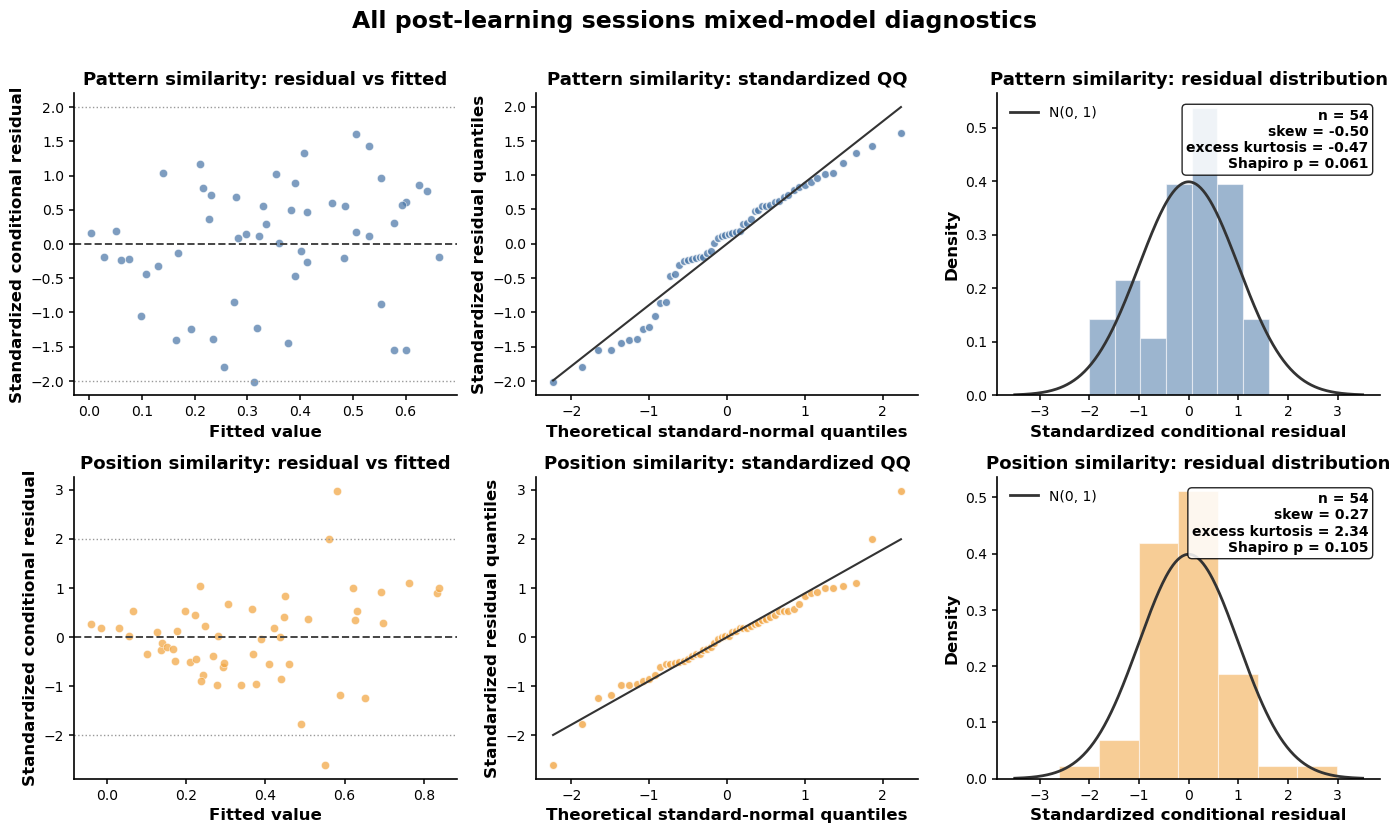

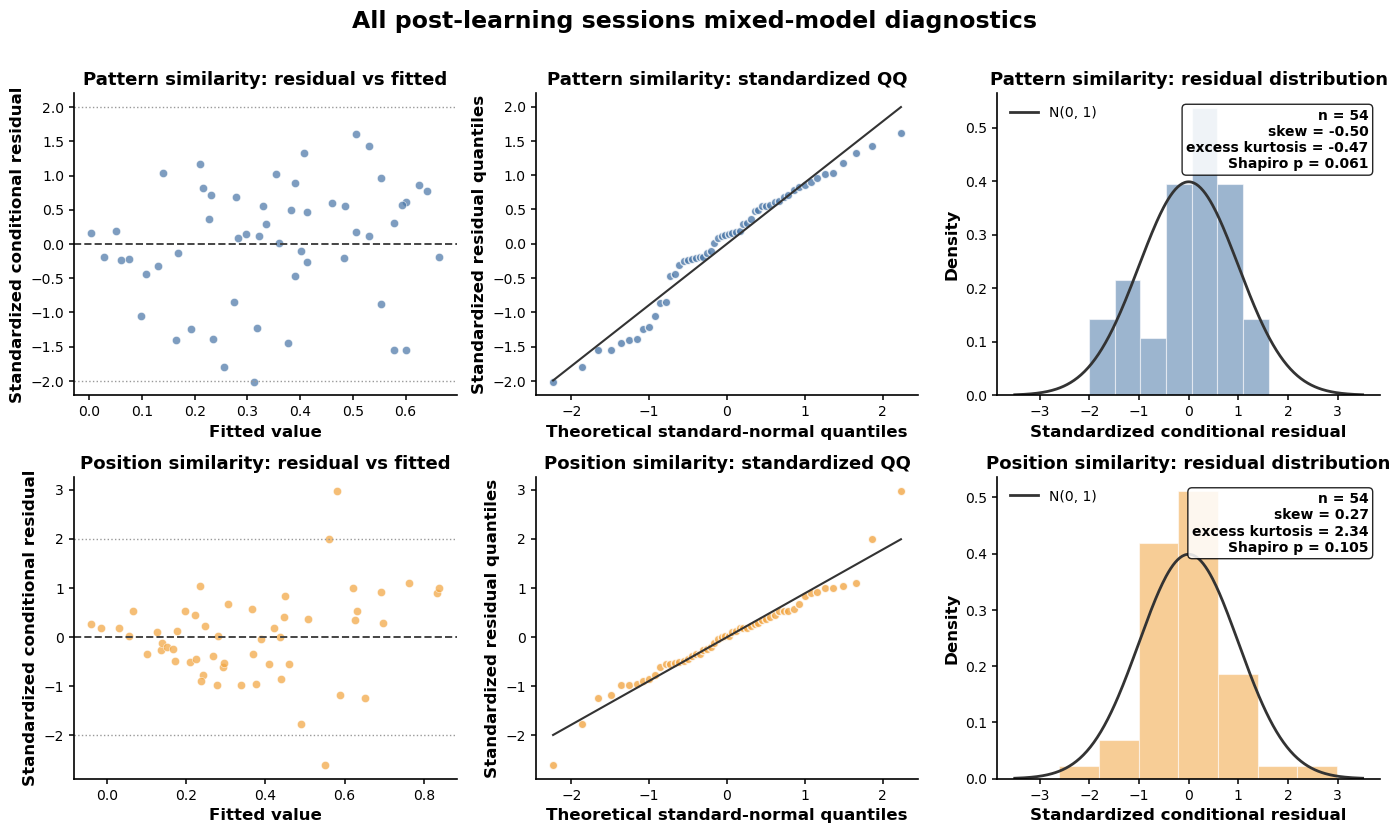

In [56]:
print(
    f"Diagnostics for {analysis_range_label} using "
    f"{RANDOM_EFFECT_STRUCTURE}"
)
diagnostic_figure, diagnostic_axes = plot_model_diagnostics(
    post_models,
    title=f"{analysis_range_label} mixed-model diagnostics",
)
for metric, output in post_models.items():
    print(
        metric,
        "structure=", output.get("random_effect_structure"),
        "converged=", output.get("converged"),
        "singular=", output.get("singular"),
        "warnings=", output.get("warning_messages", ""),
    )
diagnostic_figure


All post-learning sessions: Pattern similarity


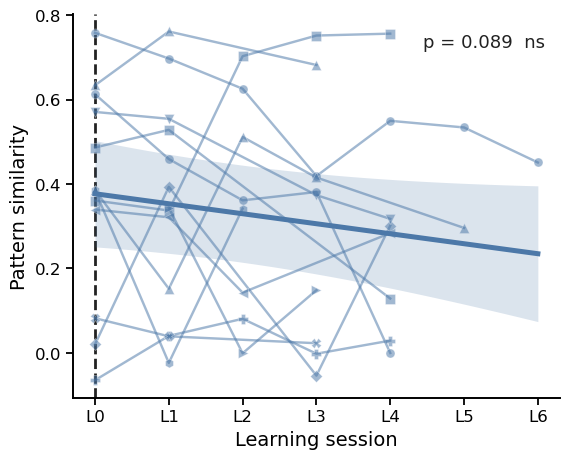

All post-learning sessions: Position similarity


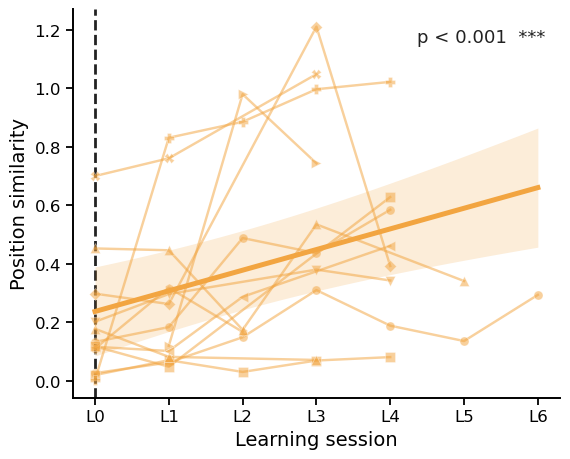

In [57]:
from IPython.display import display as display_inline

print(f"{analysis_range_label}: Pattern similarity")
pattern_figure, pattern_axis = plt.subplots(figsize=(5.8, 4.7))
plot_longitudinal_similarity(
    analysis_long,
    selected_models["pattern"],
    similarity_type="pattern",
    ax=pattern_axis,
    detailed=True,
)
pattern_figure.tight_layout()
display_inline(pattern_figure)
plt.close(pattern_figure)

print(f"{analysis_range_label}: Position similarity")
position_figure, position_axis = plt.subplots(figsize=(5.8, 4.7))
plot_longitudinal_similarity(
    analysis_long,
    selected_models["position"],
    similarity_type="position",
    ax=position_axis,
    detailed=True,
)
position_figure.tight_layout()
display_inline(position_figure)
plt.close(position_figure)
